# Relatório: Q-Learning x SARSA no Taxi-v4

Este relatório compara **Q-Learning** e **SARSA** tabulares no ambiente `Taxi-v4` do Gymnasium, em duas versões:

- **Determinístico**: cada ação move o táxi exatamente na direção escolhida.
- **Estocástico** (`is_rainy=True, rainy_probability=0.6`): o táxi vai na direção pretendida com 60% de probabilidade e escorrega para cada lado com 20%.

**Recompensas do ambiente:** -1 por passo, +20 ao entregar o passageiro no destino e -10 por *pickup*/*dropoff* ilegal. O episódio termina na entrega ou é truncado em 200 passos.

Os quatro experimentos usam os mesmos hiperparâmetros:

| Parâmetro | Valor |
|---|---|
| α (taxa de aprendizado) | 0.5 |
| γ (fator de desconto) | 0.7 |
| ε (exploração) | começa em 0.2 e é multiplicado por 0.99 a cada episódio até o mínimo de 0.05 (atingido em ~140 episódios) |
| Episódios por run | 10.000 |
| Runs (seeds independentes) | 5 |

As recompensas por episódio de cada run são geradas pelos notebooks de `taxidriver_deterministic/` e `taxidriver_stochastic/` e salvas em `data/rewards/`. Este notebook só carrega esses dados. As funções de análise ficam em `report_utils.py`.

In [1]:
from pathlib import Path

from report_utils import load_rewards, plot_comparison, summary_table

REWARDS_DIR = Path.cwd().parent / "data" / "rewards"

In [2]:
REWARD_GOAL = 8

LABELS = {
    "qlearning_deterministic": "Q-Learning (determinístico)",
    "sarsa_deterministic":     "SARSA (determinístico)",
    "qlearning_stochastic":    "Q-Learning (estocástico)",
    "sarsa_stochastic":        "SARSA (estocástico)",
}

rewards = {name: load_rewards(REWARDS_DIR, name) for name in LABELS}

## Métricas da tabela

**Convenções:**
- **Curva média**: recompensa de cada episódio, com a média tirada entre as 5 runs.
- **MM**: média móvel de 100 episódios da curva média.
- **Últ. 1000**: os últimos 1000 dos 10.000 episódios, que representam o comportamento depois do treino.

Todas as recompensas são **de treino**, isto é, foram coletadas com a exploração ε-greedy ainda ativa (ε = 0.05 no final).

| Coluna | Como é calculada | O que responde |
|---|---|---|
| **Média 1º–1000º ep.** | Média da curva média nos primeiros 1000 episódios | Quanto o agente "paga" para aprender. Um valor menos negativo indica aprendizado mais rápido. |
| **Média últimos 1000 ep.** | Média de todos os episódios de todas as runs nos últimos 1000 | Desempenho final. É a métrica principal de qualidade da política. |
| **Desvio entre runs (últ. 1000)** | Calcula a média de cada run nos últimos 1000 episódios e tira o desvio padrão entre as 5 runs | Se o resultado depende da seed. Um valor baixo indica que todas as runs chegam ao mesmo lugar. |
| **Desvio da curva média (últ. 1000)** | Desvio padrão, ao longo dos episódios, da curva média nos últimos 1000 | Quanto o desempenho ainda oscila de um episódio para o outro no fim do treino. Um valor alto indica uma política instável ou um ambiente muito ruidoso. |
| **Ep. até MM ≥ -50** | Primeiro episódio em que a MM chega a -50 | Velocidade para atingir um desempenho razoável. |
| **Ep. até MM ≥ 0** | Primeiro episódio em que a MM chega a 0 | Velocidade para atingir episódios lucrativos em média. **NaN** indica que o limiar nunca foi atingido nos 10.000 episódios. |
| **% ep. com recompensa > 0** | Fração dos episódios finais com recompensa positiva | Taxa de entregas eficientes: só há lucro quando a entrega leva menos de ~20 passos, sem ações ilegais. |
| **% ep. ≥ goal** | Fração dos episódios finais com recompensa ≥ 8 (`REWARD_GOAL`) | Taxa de episódios próximos do ótimo no ambiente determinístico (rota com no máximo ~12 passos). |
| **% ep. ≤ -200 (≈ truncados)** | Fração dos episódios finais com recompensa ≤ -200 | Taxa de falha: o agente bateu o limite de 200 passos sem entregar, em geral preso em *loop*. É uma aproximação, porque muitas ações ilegais num episódio curto também poderiam somar -200, mas isso é raro. |

In [3]:
summary_table(rewards, LABELS, REWARD_GOAL)

,Média 1º–1000º ep.,Média últimos 1000 ep.,Desvio entre runs (últ. 1000),Desvio da curva média (últ. 1000),Ep. até MM ≥ -50,Ep. até MM ≥ 0,% ep. com recompensa > 0 (últ. 1000),% ep. ≥ goal (últ. 1000),"% ep. ≤ -200 (≈ truncados, últ. 1000)"
Configuração,,,,,,,,,
Q-Learning (determinístico),-33.71,5.33,0.04,2.72,223.0,445.0,83.06,41.24,0.00
SARSA (determinístico),-149.49,-97.26,16.08,49.00,NaN,NaN,37.02,17.18,39.76
Q-Learning (estocástico),-75.95,-14.41,1.17,8.70,460.0,NaN,20.56,5.20,0.06
SARSA (estocástico),-206.80,-181.98,8.22,37.18,NaN,NaN,3.50,1.50,72.90


## Leitura da tabela

**1. O Q-Learning supera o SARSA nos dois ambientes, em todas as métricas.**
- No determinístico, a média final é 5.3 contra -97.3, e os episódios truncados são 0% contra 39.8%.
- No estocástico, a média final é -14.4 contra -182.0, e os episódios truncados são 0.06% contra 72.9%.
- A diferença é muito maior que a variação entre runs, então não é efeito de seed.

**2. O SARSA não converge.** Ele não perde por fazer rotas um pouco piores. O desempenho dele é **bimodal**: ou entrega, ou fica em *loop* até o limite de 200 passos.
- Isso aparece na coluna de truncados (40% a 73%).
- Também aparece no desvio da curva média, que é alto (37 a 49).
- Os marcos de MM nunca são atingidos (NaN).

**3. A estocasticidade piora os dois algoritmos, mas o SARSA muito mais.**
- No Q-Learning, a média final cai ~20 pontos, o tempo até MM ≥ -50 dobra (223 → 460 episódios) e os truncados continuam praticamente nulos.
- No SARSA, os truncados quase dobram (40% → 73%).
- Parte da queda é inevitável. Com 40% de chance de escorregar, a mesma rota exige em média ~1.7× mais passos, e o goal de 8 deixa de ser alcançável na prática (só 5% dos episódios do Q-Learning chegam lá). No ambiente estocástico, a comparação que faz sentido é entre os algoritmos, não contra o goal.

**4. O Q-Learning determinístico fica abaixo do goal (5.3 < 8), mas isso não indica uma política ruim.**
- As recompensas são de treino, com ε = 0.05 ainda ativo.
- Cada ação aleatória tem 2/6 de chance de ser um *pickup*/*dropoff* ilegal (-10).
- Uma avaliação greedy (ε = 0) provavelmente ficaria próxima de 8.

## Curvas de aprendizado

**Como ler os gráficos:**
- **Linha clara**: curva média bruta.
- **Linha grossa**: MM de 100 episódios.
- **Tracejado**: goal (8).
- **Quadro interno**: amplia os primeiros 1000 episódios, onde as curvas mais se diferenciam.

O sinal de convergência é a linha grossa ficar horizontal. Se ela ficar horizontal num nível baixo, o agente estagnou numa política ruim.

### Q-Learning x SARSA: Taxi determinístico

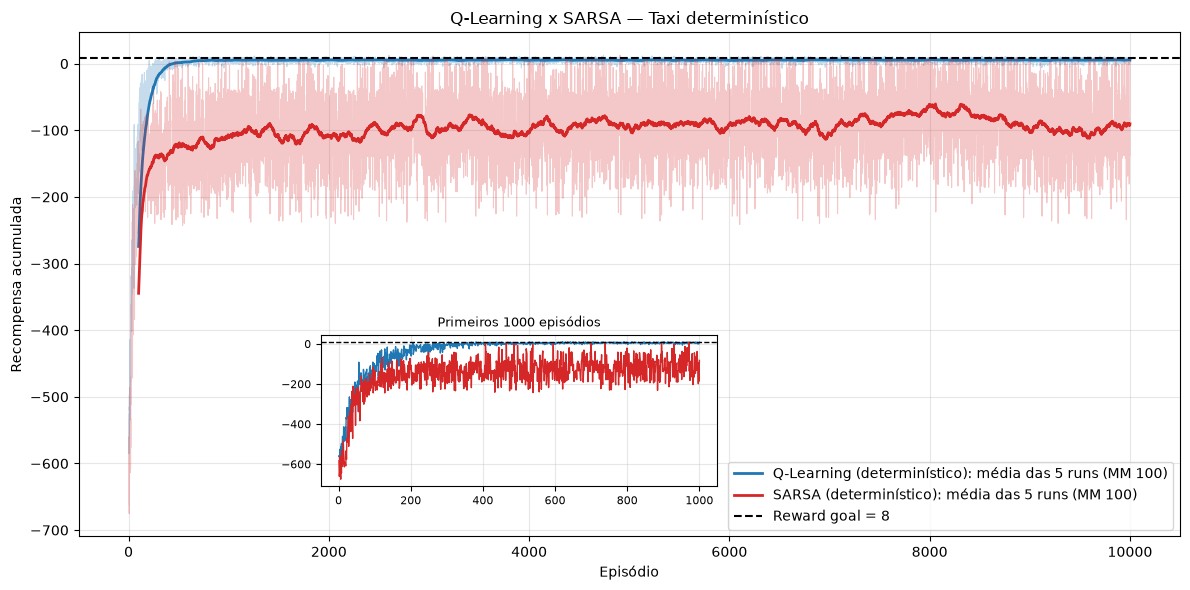

In [4]:
plot_comparison(rewards, LABELS, ["qlearning_deterministic", "sarsa_deterministic"], "Q-Learning x SARSA — Taxi determinístico", REWARD_GOAL)

- **Início (quadro interno):** os dois começam em torno de -550. A Q-table começa zerada, então o agente testa ações quase ao acaso, incluindo *pickups*/*dropoffs* ilegais (-10 cada), e os episódios são truncados em 200 passos.
- **Q-Learning (azul):** a MM sobe rápido: -274 no episódio 100, -17 no 300 e ~5 no 500. A partir do episódio ~1000 fica plana entre 5 e 6 até o fim, o que indica convergência. A faixa clara é estreita: em 90% dos episódios finais a curva média fica entre 0 e 9, ou seja, o comportamento é quase sempre o mesmo.
- **SARSA (vermelho):** acompanha o Q-Learning só nos primeiros ~150 episódios. Depois a melhora quase para: -162 no episódio 200, -122 no 500 e -110 no 1000. Dali em diante a MM oscila entre -118 e -60 sem tendência de subida.
- **A faixa clara do SARSA é larga** (de -182 a -14). Cada ponto é a média de 5 runs que misturam episódios entregues (recompensa perto de 0) e episódios presos em *loop* (≤ -200). É a forma visual dos 40% de truncados da tabela.
- **A linha do goal** só é alcançada pelo Q-Learning, e mesmo assim fica um pouco abaixo (5.3 contra 8) por causa da exploração residual (ε = 0.05).

### Q-Learning x SARSA: Taxi estocástico

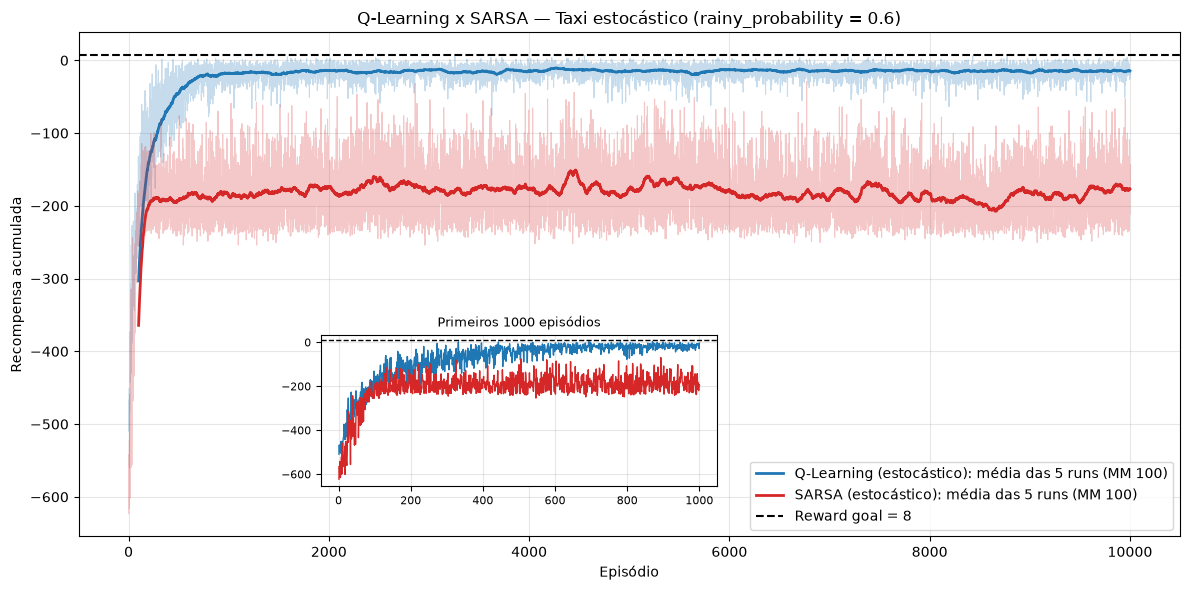

In [5]:
plot_comparison(rewards, LABELS, ["qlearning_stochastic", "sarsa_stochastic"], "Q-Learning x SARSA — Taxi estocástico (rainy_probability = 0.6)", REWARD_GOAL)

- **Q-Learning (azul):** a mesma forma do caso determinístico, porém mais lenta e mais baixa. A MM passa por -303 no episódio 100, -93 no 300, -45 no 500 e -18 no 1000, e estabiliza entre -20 e -11.
- **A faixa clara do Q-Learning ficou mais larga** que no determinístico (de -30 a -2). Esse ruído vem da chuva, não de falha do agente: ele praticamente não trunca episódios (0.06%). Só que a mesma rota ora leva poucos passos, ora leva muitos, dependendo dos escorregões.
- **SARSA (vermelho):** chega a ~-200 no episódio 200 e para ali. Depois do episódio 2000 a MM fica entre -207 e -151 e nunca alcança nem -150. A curva fica colada no patamar de episódios truncados: 73% deles não terminam a entrega.
- **A linha do goal** está fora de alcance para os dois. Com 40% de chance de escorregar, o retorno ótimo esperado fica bem abaixo de 8. Neste ambiente, o que importa é a distância entre as duas curvas, não a distância até o goal.

### Q-Learning: determinístico x estocástico

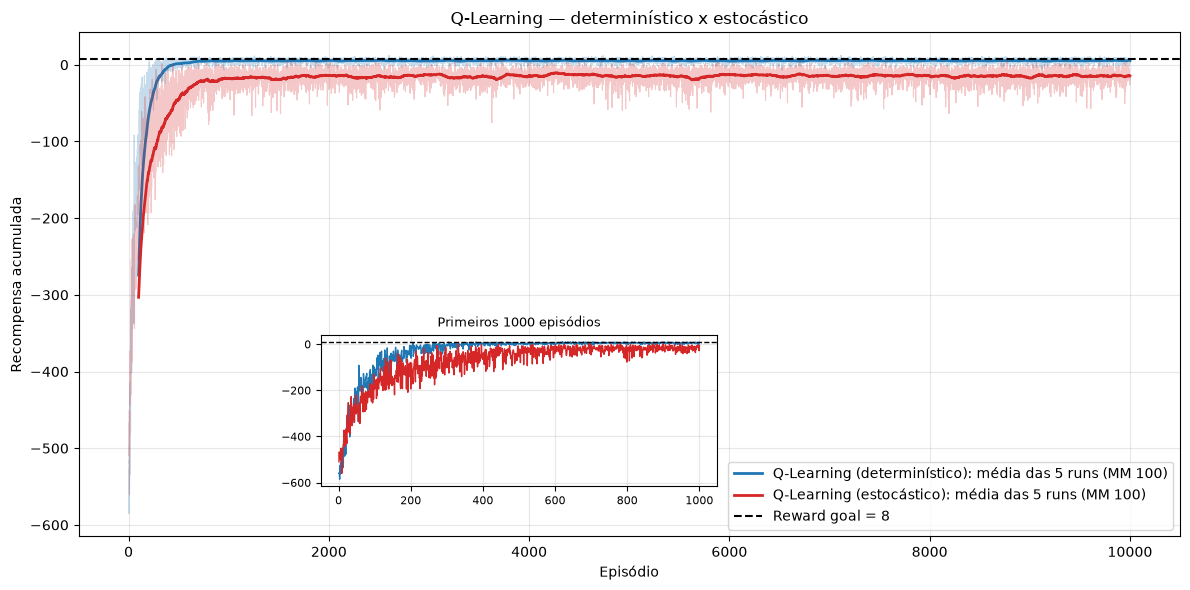

In [6]:
plot_comparison(rewards, LABELS, ["qlearning_deterministic", "qlearning_stochastic"], "Q-Learning — determinístico x estocástico", REWARD_GOAL)

- **As duas curvas têm a mesma forma.** A estocástica está deslocada para a **direita**, porque aprende mais devagar (MM ≥ -50 no episódio 460 contra 223), e para **baixo**, porque estabiliza ~20 pontos abaixo (-14 contra 5).
- **As duas ficam planas no fim**: a do determinístico a partir do episódio ~1000 e a do estocástico a partir do ~2000. Nos dois ambientes o Q-Learning converge.
- **A diferença final é o custo da chuva, não falha de aprendizado.** Nenhuma das duas curvas trunca episódios no final. Com 40% de escorregões, cada entrega simplesmente exige mais passos (≈ 1.7× em média), e cada passo custa -1.
- **A faixa clara mais larga do estocástico** mostra que, mesmo com a política convergida, o retorno de cada episódio varia mais, porque a variância agora vem do ambiente.

### SARSA: determinístico x estocástico

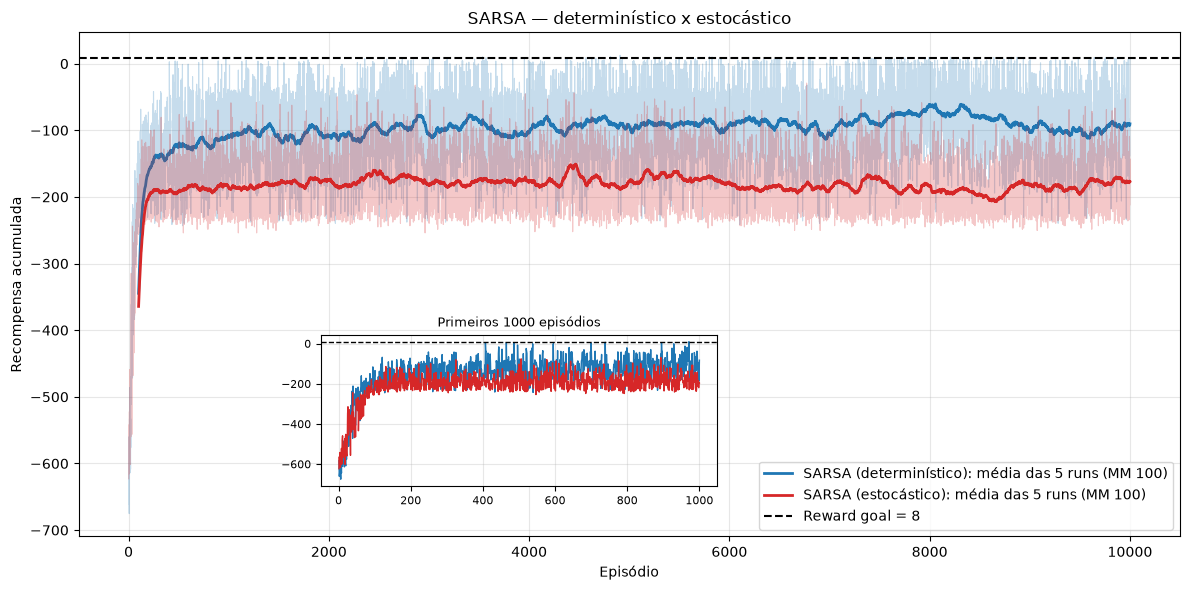

In [7]:
plot_comparison(rewards, LABELS, ["sarsa_deterministic", "sarsa_stochastic"], "SARSA — determinístico x estocástico", REWARD_GOAL)

- **As duas curvas estagnam cedo**, por volta dos episódios 300 a 500, e não sobem mais até o episódio 10.000. O patamar é ~-110 no determinístico e ~-185 no estocástico. É a evidência visual de que mais episódios não resolveriam (ver a seção *Mais episódios melhorariam o SARSA?*).
- **A curva estocástica fica perto do patamar de -200**, o valor de um episódio truncado sem ações ilegais. A maioria dos episódios (73%) termina sem entrega.
- **A curva determinística oscila mais** (MM entre -118 e -60). Os episódios se dividem entre entregas e *loops*, e a proporção varia ao longo do treino sem tendência definida.
- **A chuva amplifica o problema** que o SARSA já tinha. O sinal da recompensa de entrega, já fraco com γ = 0.7, fica ainda mais escondido pelo ruído das transições (ver a seção *Por que o SARSA falha*).

## Por que o SARSA falha: o papel de γ

γ é o **fator de desconto**: ele define quanto uma recompensa futura vale hoje. O agente maximiza o retorno descontado

$$G = r_0 + \gamma\, r_1 + \gamma^2 r_2 + \gamma^3 r_3 + \dots$$

ou seja, uma recompensa que chega daqui a $d$ passos é multiplicada por $\gamma^d$. Um jeito prático de interpretar γ é pelo **horizonte efetivo**, de aproximadamente $1/(1-\gamma)$ passos:
- com γ = 0.7, o horizonte é ≈ 3.3 passos;
- com γ = 0.99, o horizonte é ≈ 100 passos.

No Taxi, uma entrega típica leva de 10 a 15 passos, e o +20 só chega no final. A tabela mostra quanto esse +20 vale quando a entrega está a $d$ passos:

| $d$ | γ = 0.7 | γ = 0.99 |
|---|---|---|
| 5 | 3.4 | 19.0 |
| 10 | 0.56 | 18.1 |
| 15 | 0.09 | 17.2 |

Com γ = 0.7, a partir de ~10 passos o agente praticamente não "enxerga" a recompensa da entrega. O que domina são as penalidades de -1 por passo, que somam no máximo $-1/(1-0.7) \approx -3.3$.

**Consequência.** Compare o valor de estar a 10 passos da entrega com o de estar a 11, ou seja, uma ação que aproxima contra uma que afasta:
- γ = 0.7: Q ≈ -2.68 contra -2.87, uma **diferença de ≈ 0.2**.
- γ = 0.99: Q ≈ 8.5 contra 7.4, uma **diferença de ≈ 1.1**.

Longe do objetivo, todas as ações parecem quase igualmente boas. Para escolher a certa, o algoritmo precisa estimar essa diferença pequena com precisão. Aí os dois algoritmos se separam:
- **Q-Learning** atualiza com $\max_a Q(s', a)$, o valor da melhor ação seguinte. No ambiente determinístico esse alvo é praticamente sem ruído, então diferenças pequenas ainda são aprendidas.
- **SARSA** atualiza com $Q(s', a')$, onde $a'$ é a ação que a política ε-greedy realmente escolheu. O alvo carrega o ruído da exploração e, com α = 0.5 (atualizações grandes), esse ruído é maior que a diferença de ~0.2 entre as ações. O agente não consegue distinguir a ação certa e entra em *loops* até ser truncado.

No ambiente estocástico, o escorregão adiciona ainda mais ruído ao alvo dos dois algoritmos. Isso é coerente com o SARSA piorando muito mais que o Q-Learning.

## Mais episódios melhorariam o SARSA?

**Não.** Os dados indicam que o SARSA estagnou cedo, e não que estivesse aprendendo devagar.

**Média de recompensa por bloco de 1000 episódios** (calculada a partir dos mesmos CSVs, com média entre as 5 runs):

| Bloco | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 |
|---|---|---|---|---|---|---|---|---|---|---|
| SARSA determinístico | -150 | -105 | -100 | -98 | -91 | -91 | -93 | -80 | -82 | -97 |
| SARSA estocástico | -207 | -180 | -175 | -178 | -176 | -172 | -187 | -183 | -191 | -182 |
| Q-Learning estocástico (referência) | -76 | -16 | -15 | -15 | -14 | -15 | -14 | -14 | -15 | -14 |

- O ganho relevante acontece só do bloco 1 para o 2. Daí em diante, o SARSA oscila sem tendência: sobe e desce dentro da faixa do ruído.
- Ajustando uma reta aos últimos 5000 episódios de cada run, a inclinação média é de -0.3 por 1000 episódios no determinístico e de -2.3 no estocástico. Não há melhora detectável.
- Nenhuma run escapa do padrão: mesmo a melhor run do SARSA determinístico ainda trunca 32% dos episódios finais.

**Por que estagna.** O ε atinge o mínimo de 0.05 em ~140 episódios ($0.2 \cdot 0.99^n = 0.05 \Rightarrow n \approx 138$). A partir daí ε e α ficam constantes e nada no algoritmo muda com o tempo. O SARSA chega a um equilíbrio ruim e permanece nele, e mais episódios só repetem a mesma situação.

**Teste exploratório: variando γ e α no SARSA.** Este teste foi rodado fora deste notebook, com 3 seeds e 5000 episódios cada, e as métricas são dos últimos 1000 episódios. As demais configurações são iguais às do experimento principal.

| Ambiente | γ | α | Média final | % truncados |
|---|---|---|---|---|
| Determinístico | 0.7 | 0.5 | -89.3 | 36.1 |
| Determinístico | 0.99 | 0.5 | 3.3 | 0.0 |
| Determinístico | 0.99 | 0.1 | **5.1** | 0.0 |
| Estocástico | 0.7 | 0.5 | -180.1 | 71.9 |
| Estocástico | 0.99 | 0.5 | -23.2 | 0.3 |
| Estocástico | 0.99 | 0.1 | **-12.3** | 0.0 |

- A linha com γ = 0.7 reproduz o resultado do experimento principal.
- Trocar só γ de 0.7 para 0.99 elimina os *loops* nos dois ambientes.
- Com α = 0.1, o SARSA atinge o mesmo nível do Q-Learning do experimento principal (5.3 no determinístico e -14.4 no estocástico), com metade dos episódios.

Isso confirma que o limite do SARSA é a configuração, principalmente o γ, e não o tempo de treino.

## Limitações

- **Só 5 runs por configuração.** O desvio entre runs é calculado sobre 5 amostras, e as diferenças pequenas devem ser lidas com cautela. As diferenças grandes entre Q-Learning e SARSA não são afetadas por isso.
- **Métricas de treino, não de avaliação.** Os números incluem o efeito da exploração (ε = 0.05). Uma avaliação greedy separaria a qualidade da política do custo de explorar.
- **Uma única configuração de hiperparâmetros, sem ajuste.** O mesmo α, γ e ε para os dois algoritmos não é neutro: como mostra o teste exploratório, γ = 0.7 prejudica muito mais o SARSA.
- **O goal de 8 só faz sentido no ambiente determinístico.** Com chuva, o retorno ótimo esperado é bem menor.
- **Os episódios truncados são aproximados** pelo critério recompensa ≤ -200.
- **O teste exploratório (γ = 0.99) usa menos seeds e episódios** e não está reproduzido neste notebook.

## Conclusão

Com γ = 0.7 e α = 0.5:
- O **Q-Learning** aprende rápido, converge para uma política próxima do ótimo de forma consistente entre seeds e se mantém robusto quando o ambiente fica estocástico: o desempenho cai, mas ele praticamente nunca fica preso (≤ 0.06% de truncados).
- O **SARSA**, nas mesmas condições, estagna nos primeiros ~2000 episódios e fica preso em *loops* em 40% (determinístico) a 73% (estocástico) dos episódios.

A causa principal não é o número de episódios, e sim o **horizonte curto imposto por γ = 0.7**. Ele torna os valores das ações quase indistinguíveis longe do objetivo. O alvo *off-policy* do Q-Learning ($\max$) ainda consegue separá-los. O alvo *on-policy* do SARSA, mais ruidoso, não consegue.

Com γ = 0.99, o SARSA alcança desempenho equivalente ao do Q-Learning. A conclusão mais precisa é, portanto: **o Q-Learning é mais robusto a um fator de desconto inadequado e a alvos ruidosos**, e não que ele seja intrinsecamente superior ao SARSA nesta tarefa.